# Ghost Band Research

This notebook replays the V2 VWAP engine on historical US100 M1 data to study how the Gaussian ghost bands behave alongside the solid bands.

## 1. Load 2025 and define the New York window

Use 90 minutes of pre-anchor context for the solid band width. Anchor VWAP
at 09:00 New York time, warm up for 30 minutes, and study the candles from
09:30 up to the 12:30 cutoff.

In [3]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.config import CONFIG
from src.engine import EngineState, update_engine_state
from src.loaders import load_mt5_csv
from src.replay import run_replay

NY_TZ = "America/New_York"
CSV_PATH = CONFIG["data_dir"] / "2025_full_year.csv"

SOLID_PRE_ANCHOR_MINUTES = 90
WARMUP_MINUTES = 30
TRADE_OPEN = "09:30"
TRADE_CUTOFF = "12:30"

bars = (
    load_mt5_csv(str(CSV_PATH))
    .drop_duplicates(subset="datetime")
    .set_index("datetime")
    .sort_index()
    .tz_convert(NY_TZ)
)

✅ MT5 CSV loaded: 348,793 bars from C:\GitHub Projects\VWAP-probability-band-engine-v3\data\historical\2025_full_year.csv


## 2. Replay each session minute by minute

Start a fresh engine each day. Check the 09:30 VWAP against the
tick-volume-weighted average of the 30 warmup candles. Pair each candle
in the research window with the band snapshot from the previous close.

In [4]:
probability_table = pd.DataFrame(columns=["zone"])
sessions = []
skipped_days = []

for day, day_bars in bars.groupby(bars.index.date):
    trade_open = pd.Timestamp(f"{day} {TRADE_OPEN}", tz=NY_TZ)
    cutoff = pd.Timestamp(f"{day} {TRADE_CUTOFF}", tz=NY_TZ)
    anchor = trade_open - pd.Timedelta(minutes=WARMUP_MINUTES)
    context_start = anchor - pd.Timedelta(minutes=SOLID_PRE_ANCHOR_MINUTES)

    required = pd.date_range(context_start, cutoff, freq="min", inclusive="left")
    missing = required.difference(day_bars.index)
    if len(missing):
        skipped_days.append({"session_date": day, "missing_bars": len(missing)})
        continue

    replay_bars = day_bars.loc[required].rename_axis("datetime")
    config = {**CONFIG, "vwap_anchor_utc": anchor}
    rows = []

    for state in run_replay(
        replay_bars.reset_index(),
        config,
        probability_table,
        EngineState=EngineState,
        update_engine_state=update_engine_state,
        speed=100_000,
    ):
        rows.append({
            "datetime": state.datetime,
            "vwap": state.reference,
            **{f"solid_{key}": value for key, value in state.bands.items()},
            **{f"ghost_{key}": value for key, value in state.ghost_bands.items()},
        })

    snapshots = pd.DataFrame(rows).set_index("datetime")
    seed = replay_bars.loc[(required >= anchor) & (required < trade_open)]
    expected_vwap = np.average(seed["typical_price"], weights=seed["tick_volume"])

    candles = replay_bars.loc[required >= trade_open, ["open", "high", "low", "close"]]
    session = candles.join(snapshots.shift(1))

    assert np.isclose(session["vwap"].iloc[0], expected_vwap, rtol=0, atol=1e-8)
    sessions.append(session.assign(session_date=day))

if not sessions:
    raise ValueError("No dates have the full pre-anchor, warmup and trading window.")

trade_bars = pd.concat(sessions)
print(f"Replayed {len(sessions)} dates and {len(trade_bars):,} trading-window candles.")
print(f"Skipped {len(skipped_days)} dates with incomplete coverage.")

Replayed 254 dates and 45,720 trading-window candles.
Skipped 58 dates with incomplete coverage.


## 3. Plot the levels available at each candle open

Pair each candle with the VWAP and band levels calculated at the previous close. This is the timing we'll use to test whether a wick reached a band that was already visible.

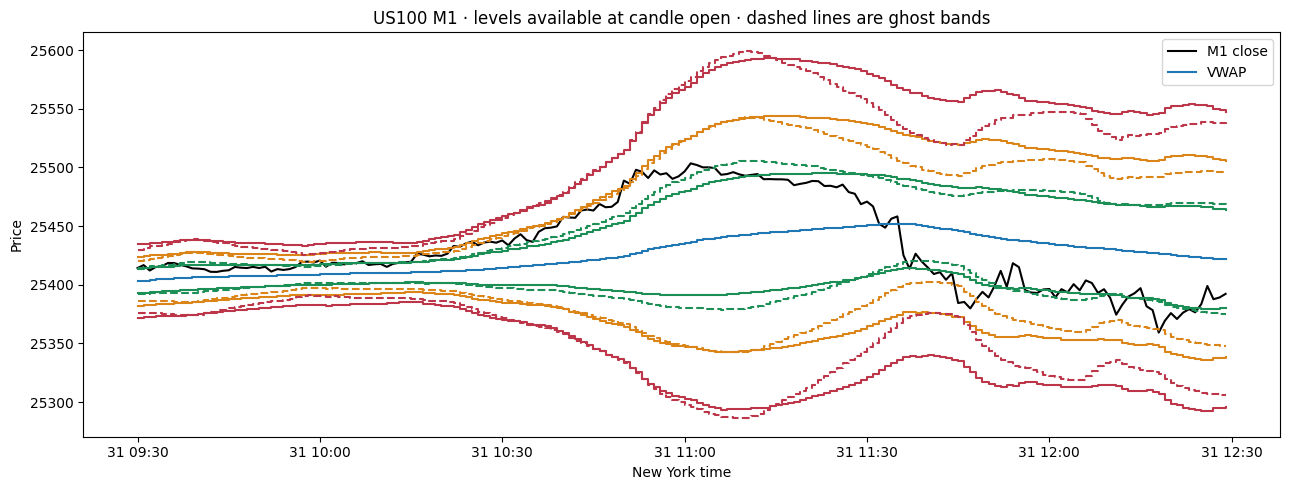

In [5]:
plot_day = trade_bars["session_date"].iloc[-1]
chart = trade_bars.loc[trade_bars["session_date"] == plot_day]

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(chart.index, chart["close"], color="black", label="M1 close")
ax.step(chart.index, chart["vwap"], where="post", color="tab:blue", label="VWAP")

colors = ["#1b8f56", "#db8519", "#bd3549"]
for level, color in enumerate(colors, start=1):
    for sign in ("+", "-"):
        ax.step(chart.index, chart[f"solid_{level}{sign}"], where="post", color=color)
        ax.step(
            chart.index,
            chart[f"ghost_{level}{sign}"],
            where="post",
            color=color,
            linestyle="--",
        )

ax.set_title("US100 M1 · levels available at candle open · dashed lines are ghost bands")
ax.set_xlabel("New York time")
ax.set_ylabel("Price")
ax.legend()
fig.tight_layout()
plt.show()

## 4. Label green-band wick setups

A long wick setup opens above upper green, touches it, and closes back
above it. A short setup mirrors this at lower green. Each candle is
tested against the solid and ghost levels available at its open.

Classify each setup as solid only, ghost only, or both. A label describes
which band satisfied the full wick rule.

In [6]:
def green_wick_flags(bars, band_set):
    upper = bars[f"{band_set}_1+"]
    lower = bars[f"{band_set}_1-"]

    long_wick = (
        bars["open"].gt(upper)
        & bars["low"].le(upper)
        & bars["close"].gt(upper)
    )
    short_wick = (
        bars["open"].lt(lower)
        & bars["high"].ge(lower)
        & bars["close"].lt(lower)
    )

    return {"long": long_wick, "short": short_wick}


green_columns = ["solid_1+", "solid_1-", "ghost_1+", "ghost_1-"]
comparable_bars = trade_bars.dropna(subset=green_columns)

solid_flags = green_wick_flags(comparable_bars, "solid")
ghost_flags = green_wick_flags(comparable_bars, "ghost")
event_frames = []

for side in ("long", "short"):
    solid_hit = solid_flags[side]
    ghost_hit = ghost_flags[side]
    is_event = solid_hit | ghost_hit

    events = comparable_bars.loc[is_event].copy()
    events["side"] = side
    events["setup"] = np.select(
        [(solid_hit & ghost_hit).loc[is_event], solid_hit.loc[is_event]],
        ["both", "solid_only"],
        default="ghost_only",
    )
    event_frames.append(events)

wick_events = pd.concat(event_frames).sort_index()
setup_counts = pd.crosstab(wick_events["side"], wick_events["setup"]).reindex(
    index=["long", "short"],
    columns=["solid_only", "ghost_only", "both"],
    fill_value=0,
)

display(setup_counts)

setup,solid_only,ghost_only,both
side,,,
long,1086,1092,462
short,853,932,394
